# Rolling Volatility Between Sectors

In [1]:
import pandas as pd
from pathlib import Path
import numpy as np
import pandas as pd



In [2]:

DATA_PROCESSED = Path("data_processed")

stocks = pd.read_parquet(DATA_PROCESSED / "stocks_clean.parquet")
etfs   = pd.read_parquet(DATA_PROCESSED / "etfs_clean.parquet")
meta   = pd.read_parquet(DATA_PROCESSED / "metadata_clean.parquet")


meta = meta.rename(columns={"symbol": "Symbol"})

In [3]:
def analyze_date_coverage(stocks):
    import pandas as pd

    # Compute per-symbol start and end dates
    date_ranges = stocks.groupby("Symbol")["Date"].agg(["min", "max"]).reset_index()
    date_ranges.rename(columns={"min": "start_date", "max": "end_date"}, inplace=True)

    # Convert to datetime (just to be sure)
    date_ranges["start_date"] = pd.to_datetime(date_ranges["start_date"])
    date_ranges["end_date"]   = pd.to_datetime(date_ranges["end_date"])

    print("GLOBAL earliest date:", date_ranges["start_date"].min())
    print("GLOBAL latest date:", date_ranges["end_date"].max())
    print()

    print("----- Distribution of start years -----")
    print(date_ranges["start_date"].dt.year.value_counts().sort_index())
    print()

    print("----- Distribution of end years -----")
    print(date_ranges["end_date"].dt.year.value_counts().sort_index())

    return date_ranges


In [4]:
date_ranges = analyze_date_coverage(stocks)


GLOBAL earliest date: 1962-01-02 00:00:00
GLOBAL latest date: 2020-04-01 00:00:00

----- Distribution of start years -----
start_date
1962     17
1966      1
1970      8
1972     14
1973    104
1974      2
1975      8
1976      2
1977      6
1978      4
1979      3
1980    261
1981     36
1982     20
1983     37
1984     31
1985     30
1986     68
1987     70
1988     43
1989     41
1990     39
1991     67
1992    115
1993    135
1994    141
1995    106
1996    121
1997    107
1998     98
1999    163
2000    141
2001     76
2002    103
2003    126
2004    143
2005    148
2006    140
2007    226
2008    101
2009     75
2010    165
2011    124
2012    180
2013    238
2014    303
2015    220
2016    193
2017    278
2018    324
2019    357
2020     55
Name: count, dtype: int64

----- Distribution of end years -----
end_date
2016       1
2018       1
2019       1
2020    5611
Name: count, dtype: int64


In [5]:
start_date = "2005-01-01"
end_date   = "2020-04-01"

stocks_filtered = stocks[
    (stocks["Date"] >= start_date) &
    (stocks["Date"] <= end_date)
].copy()


In [6]:
min_rows = 250

symbol_counts = stocks_filtered["Symbol"].value_counts()
good_symbols = symbol_counts[symbol_counts >= min_rows].index
print(len(good_symbols))

stocks_filtered = stocks_filtered[stocks_filtered["Symbol"].isin(good_symbols)]


5282


In [7]:
# symbols that have a non-null Sector in metadata
valid_symbols = meta.loc[meta["Sector"].notna(), "Symbol"].unique()

len(valid_symbols)  # just to see how many


3702

In [8]:
stocks_with_sector = stocks_filtered[
    stocks_filtered["Symbol"].isin(valid_symbols)
].copy()


In [9]:
stocks_sect = stocks_with_sector.merge(
    meta[["Symbol", "Sector"]],
    on="Symbol",
    how="left"
)

# sanity check
missing_rows = stocks_sect["Sector"].isna().sum()
total_rows   = len(stocks_sect)

print("Rows with missing Sector:", missing_rows)
print("Percentage:", round(missing_rows / total_rows * 100, 4), "%")


Rows with missing Sector: 0
Percentage: 0.0 %


In [10]:
stocks_sect["Symbol"].nunique()
stocks_sect["Sector"].value_counts()


Sector
Financial Services        2664274
Healthcare                1237848
Industrials               1235463
Technology                1184582
Consumer Cyclical          991784
Real Estate                512632
Basic Materials            508320
Energy                     487294
Consumer Defensive         432104
Communication Services     366824
Utilities                  246305
Name: count, dtype: int64

In [11]:
# 1) Sort properly
stocks_sect = stocks_sect.sort_values(["Symbol", "Date"])

# 2) Choose price column
price_col = "Adj Close" if "Adj Close" in stocks_sect.columns else "Close"
print("Using price column:", price_col)

# 3) Compute simple daily returns
stocks_sect["Return"] = (
    stocks_sect
    .groupby("Symbol")[price_col]
    .pct_change()
)


Using price column: Adj Close


In [12]:
stocks_sect["Return"] = stocks_sect["Return"].clip(lower=-0.5, upper=0.5)


In [13]:
stocks_sect["Return"].describe()


count    9.864084e+06
mean     4.745029e-04
std      3.701648e-02
min     -5.000000e-01
25%     -1.013517e-02
50%      0.000000e+00
75%      1.031089e-02
max      5.000000e-01
Name: Return, dtype: float64

In [14]:
stocks_sect["SectorVolume"] = (
    stocks_sect
    .groupby(["Date", "Sector"])["Volume"]
    .transform("sum")
)


In [15]:
stocks_sect["Weight"] = stocks_sect["Volume"] / stocks_sect["SectorVolume"]


# 1. Rolling Volaitility On 20 Days

In [16]:
# 4) Compute 20-day rolling volatility per symbol
window_20 = 20

stocks_sect["RollingVol20"] = (
    stocks_sect
        .groupby("Symbol")["Return"]
        .rolling(window_20)
        .std()
        .reset_index(level=0, drop=True)
)


In [17]:
stocks_sect["RollingVol20"].describe()


count    9.800510e+06
mean     2.581155e-02
std      2.642086e-02
min      0.000000e+00
25%      1.198892e-02
50%      1.889622e-02
75%      3.063488e-02
max      5.129892e-01
Name: RollingVol20, dtype: float64

In [18]:
stocks_sect["WeightedVol20"] = (
    stocks_sect["Weight"] * stocks_sect["RollingVol20"]
)


In [19]:
sector_vol_20 = (
    stocks_sect
        .groupby(["Date", "Sector"])["WeightedVol20"]
        .sum()
        .reset_index()
)


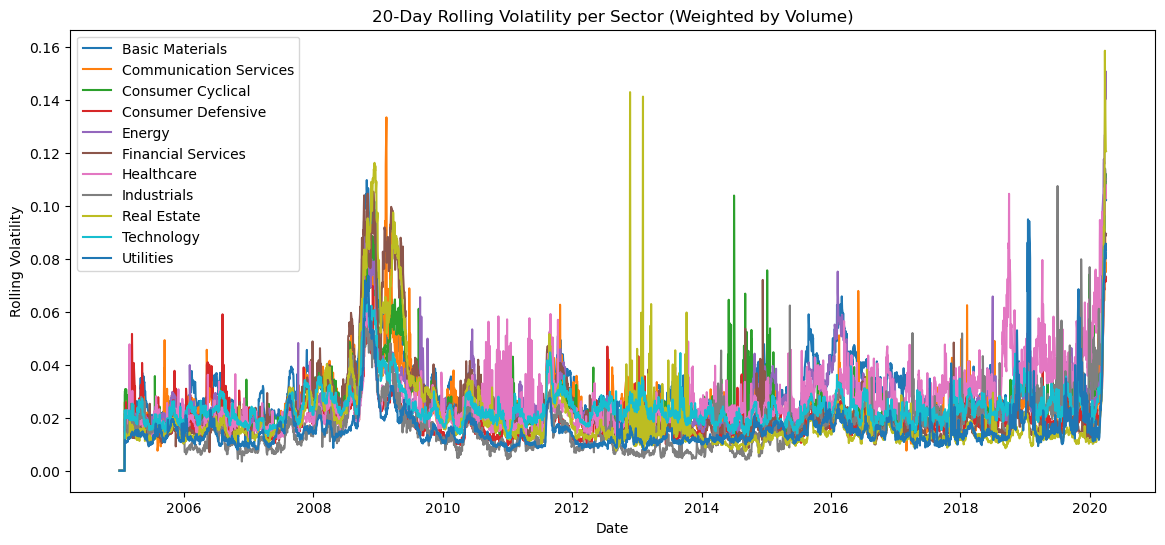

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

for sector in sector_vol_20["Sector"].unique():
    sub = sector_vol_20[sector_vol_20["Sector"] == sector]
    plt.plot(sub["Date"], sub["WeightedVol20"], label=sector)

plt.title("20-Day Rolling Volatility per Sector (Weighted by Volume)")
plt.xlabel("Date")
plt.ylabel("Rolling Volatility")
plt.legend()
plt.show()


# 2. Rolling Volaitility On 60 Days

In [21]:
# 4) Compute 60-day rolling volatility per symbol
window_60 = 60

stocks_sect["RollingVol60"] = (
    stocks_sect
        .groupby("Symbol")["Return"]
        .rolling(window_60)
        .std()
        .reset_index(level=0, drop=True)
)


In [22]:
stocks_sect["WeightedVol60"] = (
    stocks_sect["Weight"] * stocks_sect["RollingVol60"]
)


In [23]:
sector_vol_60 = (
    stocks_sect
        .groupby(["Date", "Sector"])["WeightedVol60"]
        .sum()
        .reset_index()
)


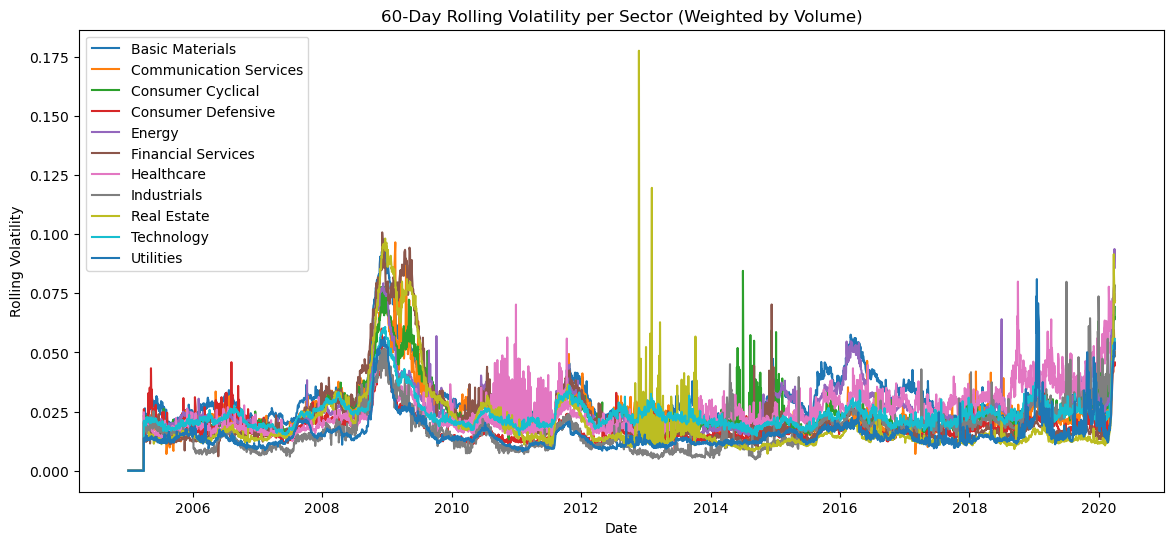

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

for sector in sector_vol_60["Sector"].unique():
    sub = sector_vol_60[sector_vol_60["Sector"] == sector]
    plt.plot(sub["Date"], sub["WeightedVol60"], label=sector)

plt.title("60-Day Rolling Volatility per Sector (Weighted by Volume)")
plt.xlabel("Date")
plt.ylabel("Rolling Volatility")
plt.legend()
plt.show()


# 2. Rolling Volaitility On 120 Days

In [25]:
# 4) Compute 120-day rolling volatility per symbol
window_120 = 120

stocks_sect["RollingVol120"] = (
    stocks_sect
        .groupby("Symbol")["Return"]
        .rolling(window_120)
        .std()
        .reset_index(level=0, drop=True)
)


In [26]:
stocks_sect["WeightedVol120"] = (
    stocks_sect["Weight"] * stocks_sect["RollingVol120"]
)


In [27]:
sector_vol_120 = (
    stocks_sect
        .groupby(["Date", "Sector"])["WeightedVol120"]
        .sum()
        .reset_index()
)


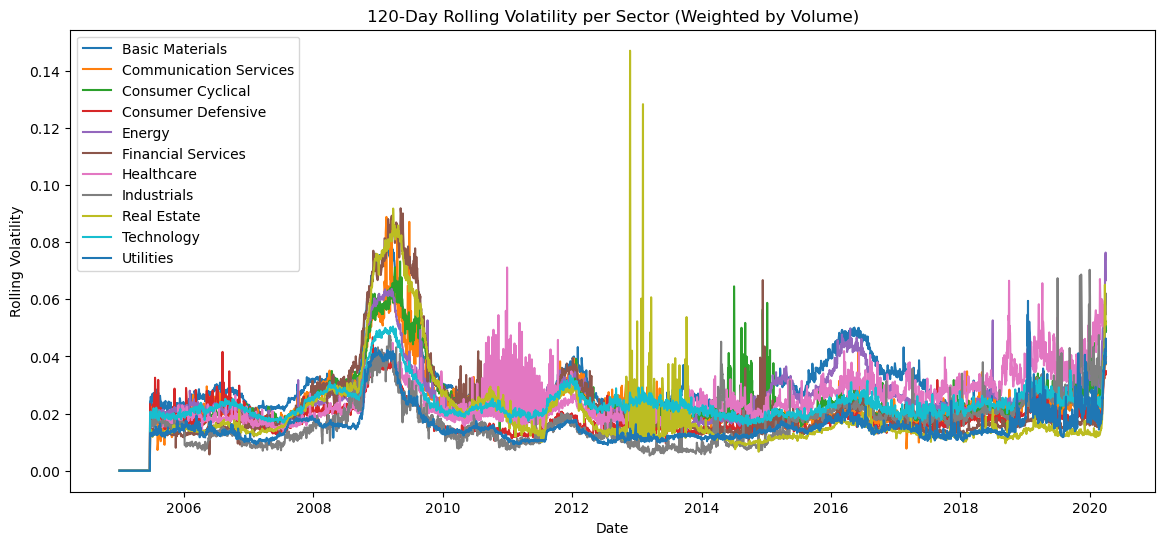

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

for sector in sector_vol_120["Sector"].unique():
    sub = sector_vol_120[sector_vol_120["Sector"] == sector]
    plt.plot(sub["Date"], sub["WeightedVol120"], label=sector)

plt.title("120-Day Rolling Volatility per Sector (Weighted by Volume)")
plt.xlabel("Date")
plt.ylabel("Rolling Volatility")
plt.legend()
plt.show()


In [29]:
stocks_sect.to_parquet("data_processed/stocks_sect.parquet")
